In [1]:
import tensorflow as tf

In [2]:
#from keras.models import sequential
from keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np
import random

In [3]:
from keras.models import Sequential

In [4]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step 


In [5]:
x_train = x_train/255
x_test = x_test/255

In [6]:
import keras
model = Sequential()

In [7]:
model.add(keras.layers.Flatten(input_shape = (28,28)))
model.add(keras.layers.Dense(128,activation = "relu"))
model.add(keras.layers.Dense(10,activation = "softmax"))

C:\Users\Hp\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [8]:
model.compile(optimizer = "sgd", loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])

In [9]:
neunet = model.fit(x_train, y_train, validation_data = (x_test, y_test), epochs = 5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8367 - loss: 0.6466 - val_accuracy: 0.9038 - val_loss: 0.3539
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9074 - loss: 0.3338 - val_accuracy: 0.9213 - val_loss: 0.2862
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9206 - loss: 0.2835 - val_accuracy: 0.9299 - val_loss: 0.2543
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9287 - loss: 0.2528 - val_accuracy: 0.9348 - val_loss: 0.2313
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9355 - loss: 0.2293 - val_accuracy: 0.9404 - val_loss: 0.2133


In [10]:
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28)
(10000, 28, 28)


In [11]:
test_loss, test_acc = model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9404 - loss: 0.2133  


In [12]:
print("loss = %.3f" % test_loss)
print("accuracy = %.3f" % test_acc)

loss = 0.213
accuracy = 0.940


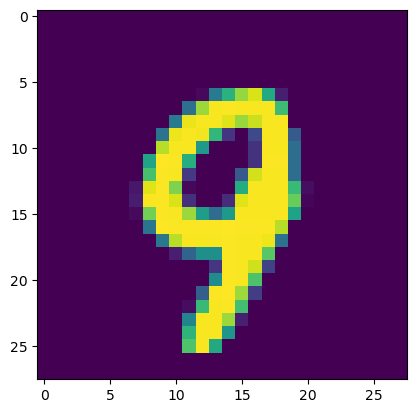

In [13]:
n = random.randint(0,9999)
plt.imshow(x_test[n])
plt.show()

In [14]:
prediction = model.predict(x_test)
print("the handwritten in the image is: ", np.argmax(prediction[n]))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  
the handwritten in the image is:  9


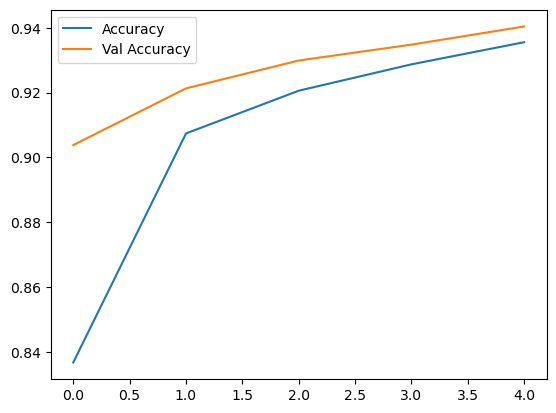

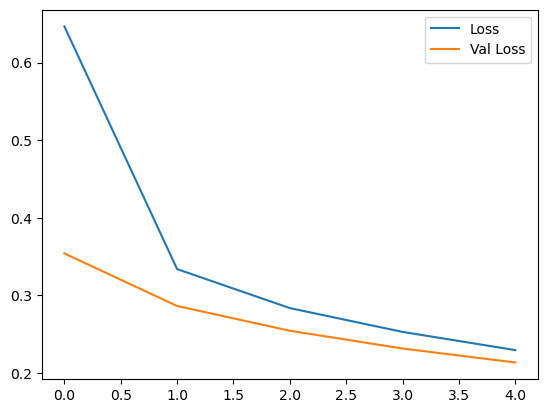

In [15]:
import matplotlib.pyplot as plt

plt.plot(neunet.history['accuracy'], label='Accuracy')
plt.plot(neunet.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.show()

plt.plot(neunet.history['loss'], label='Loss')
plt.plot(neunet.history['val_loss'], label='Val Loss')
plt.legend()
plt.show()